In [59]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast
import re
import gzip


In [78]:
def load_predictions(path=None, split=None):
    """Validated reader; use it in analyze_csv instead of pd.read_csv."""
    path = path
    if not os.path.exists(path):
        raise FileNotFoundError(path)
    df = pd.read_csv(path)
    if split is not None:
        have = sorted(df["split"].unique())
        df = df[df["split"] == split]
        if df.empty:
            raise ValueError(f"no rows for split '{split}', available: {have}")
    if not np.isfinite(df["prob"]).all():
        raise ValueError("non-finite probabilities in file")
    return df.sort_values(["run", "frame"]).reset_index(drop=True)

def alarm_idx(p, tau, k=3):
    if len(p) < k: return None
    hit = np.convolve((p > tau).astype(int), np.ones(k, int), "valid") == k
    return int(np.argmax(hit)) + k - 1 if hit.any() else None

def analyze_csv(path, split="test",
                taus=np.round(np.arange(0.6, 1.0, 0.015), 2), k=3, horizon_ns=10,
                out=None):
    df = pd.read_csv(path)
    df = df[df["split"] == split]
    runs = [(g.sort_values("frame"), r) for r, g in df.groupby("run")]

    rows = []
    for tau in taus:
        fa = ns = miss = early = ok = nu = 0
        leads = []
        for g, _ in runs:
            a = alarm_idx(g["prob"].to_numpy(), tau)
            if g["stable"].iloc[0]:
                ns += 1; fa += a is not None
            else:
                nu += 1
                if a is None: miss += 1; continue
                lead = g["unf_ps"].iloc[0] / 1000 - g["time_ns"].iloc[a]
                leads.append(lead)
                if lead > horizon_ns: early += 1
                else: ok += 1
        rows.append({"tau": tau, "k": k, "n_stable": ns, "false_alarms": fa,
                     "n_unfolding": nu, "missed": miss, "early": early, "on_time": ok,
                     "false_alarm_rate": fa / max(ns, 1),
                     "detection_rate": (nu - miss) / max(nu, 1),
                     "median_lead_ns": np.median(leads) if leads else np.nan})
    res = pd.DataFrame(rows)
    if out: res.to_csv(out, index=False)
    return res

In [79]:
gz_file = "results_real/results_031126/dihedrals_ts_v3/predictions.csv.gz"
split = 'test'
#df = load_predictions(gz_file, split)

res = analyze_csv(gz_file, split)


#print(df.tail(50))
print("-----------------------------------------------------")
print(res.to_string())
#print(recal.head(15))

-----------------------------------------------------
     tau  k  n_stable  false_alarms  n_unfolding  missed  early  on_time  false_alarm_rate  detection_rate  median_lead_ns
0   0.60  3       613           468          818      62    749        7          0.763458        0.924205          116.80
1   0.62  3       613           445          818      68    737       13          0.725938        0.916870          114.69
2   0.63  3       613           433          818      75    727       16          0.706362        0.908313          113.48
3   0.64  3       613           423          818      82    721       15          0.690049        0.899756          110.77
4   0.66  3       613           400          818     103    697       18          0.652529        0.874083          108.38
5   0.68  3       613           373          818     124    670       24          0.608483        0.848411          107.88
6   0.69  3       613           361          818     131    657       30          0.5

In [69]:
H_ns =10
Frames_ps = 20*50

def plot_traces(dataframe, tau, k=3, n_unf=8, n_stable=4):
    df = dataframe
    # 1. Filter the data first
    unf_data = df[df['unf_ps'] < 1_000_000]
    stb_data = df[df['unf_ps'] >= 1_000_000]

    unf_df = unf_data.sample(n=min(n_unf, len(unf_data)))
    stb_df = stb_data.sample(n=min(n_stable, len(stb_data)))
    unf = [((row['run'], row['unf_ps']), row['prob']) for _, row in unf_df.iterrows()]
    stb = [((row['run'], row['unf_ps']), row['prob']) for _, row in stb_df.iterrows()]
    sel = unf + stb

    if not sel:
        print("nothing to plot"); return

    cols = 4
    rows = (len(sel) + cols - 1) // cols

    # Optional: Add dpi=100 or 150 here if it's still slightly blurry in your IDE
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 2.8 * rows), squeeze=False)

    for ax in axes.ravel():
        ax.axis("off")

    for ax, ((path, unf_ps), p) in zip(axes.ravel(), sel):
        ax.axis("on")
        p = np.array(p).flatten()
        t = np.arange(len(p)) * Frames_ps / 1000                 # ns
        ax.plot(t, p, lw=1)
        ax.axhline(tau, color="gray", ls=":")
        alarm = alarm_idx(p, tau, k)

        # FIX: Use 'path' (the current run ID) instead of the whole df['run'] column
        title = f"Run: {path}"

        if unf_ps < 1_000_000:
            u = unf_ps / 1000
            ax.axvspan(u - H_ns, u, color="red", alpha=0.15)      # "close" window
            ax.axvline(u, color="red", ls="--")
            if alarm is not None:
                ax.axvline(t[alarm], color="green")
                title += f"\nlead {u - t[alarm]:.1f} ns"
            else:
                title += "\nmissed"
        else:
            title += "\nstable" + (" (false alarm)" if alarm is not None else "")
            if alarm is not None:
                ax.axvline(t[alarm], color="green")

        ax.set_title(title, fontsize=8)
        ax.set_ylim(0, 1)
        ax.set_xlabel("time (ns)", fontsize=8)
        ax.set_ylabel("P(close)", fontsize=8)

    plt.tight_layout()
    plt.show()

def plot_summary(items, probs, tau, k=3):
    taus = np.linspace(0.05, 0.99, 40)
    det, fa = [], []
    for tt in taus:
        d = n_u = f = n_s = 0
        for (path, unf_ps), p in zip(items, probs):
            a = alarm_idx(p, tt, k)
            if unf_ps >= 1_000_000:
                n_s += 1; f += a is not None
            else:
                n_u += 1; d += a is not None
        det.append(d / max(n_u, 1)); fa.append(f / max(n_s, 1))
    leads = []
    for (path, unf_ps), p in zip(items, probs):
        a = alarm_idx(p, tau, k)
        if unf_ps < 1_000_000 and a is not None:
            leads.append(unf_ps / 1000 - a * Frames_ps / 1000)

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].plot(taus, det, label="unfolding runs detected")
    ax[0].plot(taus, fa, label="stable runs with false alarm")
    ax[0].axvline(tau, color="gray", ls=":")
    ax[0].set_xlabel("threshold tau"); ax[0].set_ylabel("fraction of runs"); ax[0].legend()
    if leads:
        ax[1].hist(leads, bins=15)
    ax[1].axvline(H_ns, color="red", ls="--", label=f"horizon {H_ns} ns")
    ax[1].set_xlabel(f"lead time before unfolding (ns), tau={tau}")
    ax[1].set_ylabel("runs"); ax[1].legend()
    plt.tight_layout()
    plt.show()

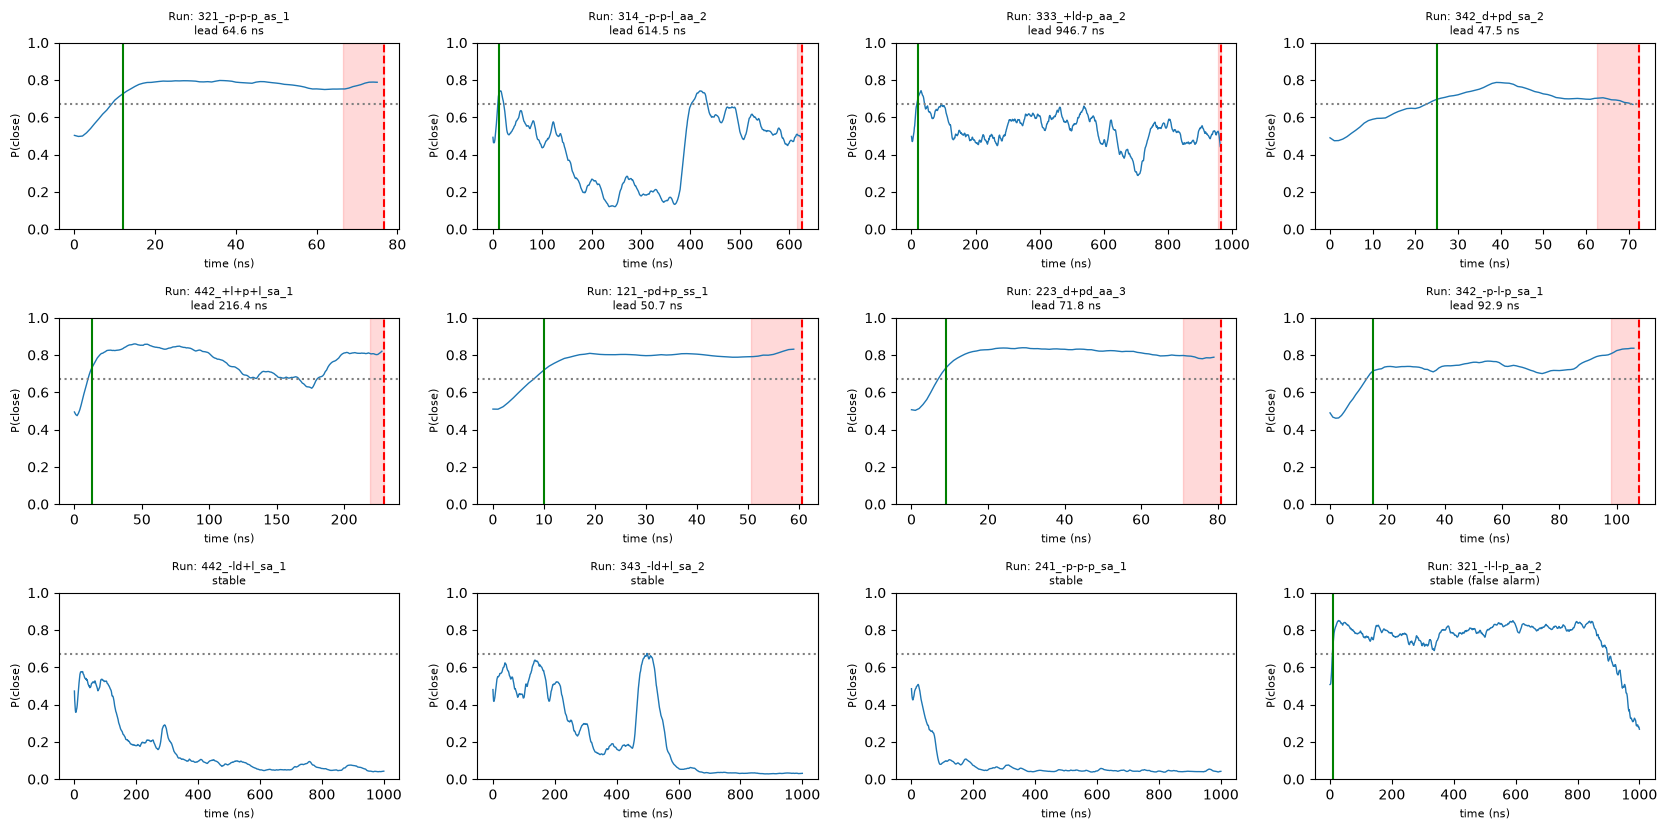

In [83]:
tau_1 = 0.67

df_raw = pd.read_csv(gz_file, compression='gzip')
df = df_raw.groupby('run').agg({
    'unf_ps': 'first',
    'prob': list
}).reset_index()
df['prob'] = df['prob'].apply(np.array)

plot_traces(df, tau=tau_1)

In [60]:
with gzip.open(gz_file, 'rt', encoding='utf-8') as f:
    print("Nagłówki:", f.readline().strip())
    print("Pierwszy wiersz:", f.readline().strip())

Nagłówki: run,split,seq,top,lay,copy,unf_ps,stable,frame,time_ns,label,prob
Pierwszy wiersz: 443_-p-p-p_as_1,train,443,-p-p-p,as,1,1000000.00000,True,0,0.00000,0.00000,0.47816
